# Aligning cell-cycle angular scores between scoring regimes

Several of us score where a cell is on the cell cycle, each in a different dataset and with a different convention. To
use the scores together (compare them, transfer a morphology clock from one dataset to another, regress the cycle out)
we need to know how they relate. This notebook does two things:

1. **Aligns the regimes**: what is the relation between the angular scores, and can it be fixed with a rotation or a re-timing?
2. **Asks how phase-contrast morphology predicts each regime**, and where around the cycle.

> **"phase" is used for two things.** *Cell-cycle phase* (G1/S/G2/M, or a continuous angle) is what the scores measure.
> *Phase-contrast* (label-free, QPI) is an imaging modality. Here phase-contrast **morphology** is only ever the predictor.

| regime | dataset | what it is | convention |
|---|---|---|---|
| **Element RNA clock** | Element A549 screen | cycleVI circular position learned from RNA only (Tim) | degrees, 0 = peak of the S score, runs toward G2/M |
| **4i DNA** | OPS0077 (Altair, A549) | closed principal curve through phospho-Rb fraction, p21, pRb **and DNA content** (Louise, the core score) | 0 to 1; 0 = G1 start (lowest DNA), runs through S to G2/M |
| **4i markers** | OPS0077 | the same kind of curve through phospho-Rb, p21 and pRb **without DNA** (Louise; her script marks it "QC only, weak without DNA") | 0 to 1, origin set by a separate alignment step |
| **4i DNA+PCs (final `cc_phase`)** | OPS0077 | the DNA curve plus principal components that track the cycle without being batch or size driven (Louise) | 0 to 1, same as 4i DNA |
| **morphology** | OPS0077 | phase-contrast morphology -> the 4i clock, held-out (ours) | same as the 4i clock it predicts |

The two datasets share **no cells**, so they cannot be compared cell by cell. Within OPS0077 the 4i regimes and our
morphology prediction are all measured on the same cells, so those can be compared directly.

In [1]:
import os, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 160)

def find(n):
    for r in ['reports/cell_cycle_alignment', 'cc_align', '.']:
        if os.path.exists(f'{r}/{n}'): return f'{r}/{n}'
    raise FileNotFoundError(n)

## 1. How the regimes within OPS0077 relate (same cells)

For every pair of regimes we find the **best rotation** (and, if it helps, a reversal of direction) that maps one onto the other,
chosen by how well the angle differences concentrate. We report the **median angular error after that alignment** (a random guess is 90 degrees)
and a **mean-cosine agreement** (1 = identical).

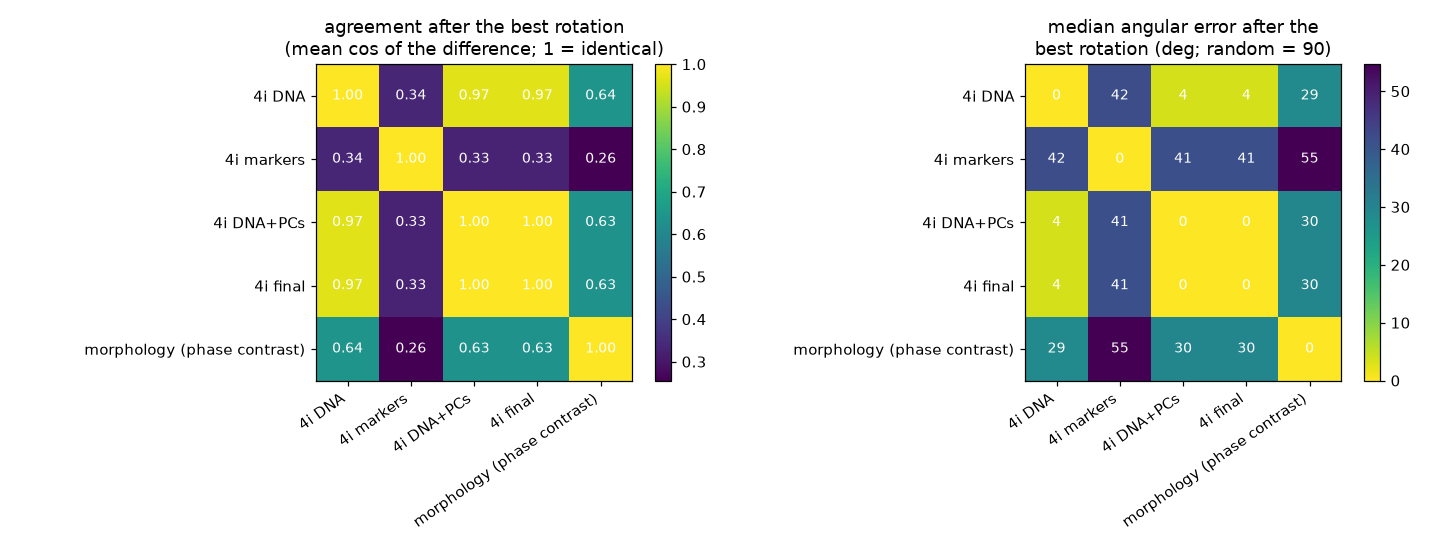

In [2]:
display(Image(filename=find('cc_align_4_regime_agreement.png')))

**The DNA-based regimes are one clock.** 4i DNA, 4i DNA+PCs and the final `cc_phase` agree with each other (within about 7 degrees). The final `cc_phase` *is* the
DNA+PCs fit.

**The markers-only regime is the same cycle in the same direction, but it needs a rotation and it is only moderately aligned.** Its stored angle sits about
**218 degrees away** from the DNA clock, and a rotation of **142 degrees** brings it to a median difference of about 40 degrees. Two details matter:

1. **Its origin is arbitrary in the stored file.** The alignment step in the scoring script scores agreement with `np.abs(mean(exp(i*diff)))`, which does not change when
   a rotation is added, so its shift search cannot choose a shift. (Rotation-sensitive version: `np.mean(np.cos(2*np.pi*diff))`.)
2. **The relation is not a single rotation everywhere.** The table and figure below show that over part of the clock (DNA angle about 0 to 60 degrees, about a third of the cells) the markers angle
   runs the opposite way, so those cells stay far from the aligned DNA clock.

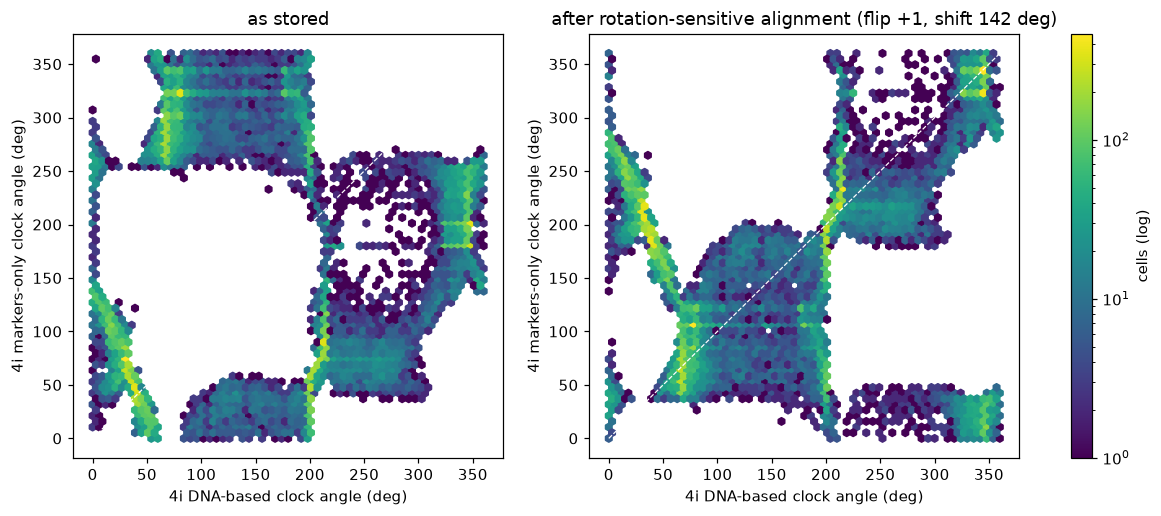

stored_resultant_length,stored_mean_offset_deg,best_flip,best_shift_deg,aligned_mean_cos,aligned_median_diff_deg
0.3360786430228752,217.7554532429703,1,142.00000000000003,0.3360755818432708,41.71435931442607



,dna_angle_deg,n,markers_mean_angle_deg,concentration
0,0-30,4304,100,0.72
1,30-60,6031,43,0.83
2,60-90,6170,301,0.90
3,90-120,1266,327,0.78
4,120-150,1014,346,0.70
5,150-180,1098,336,0.76
6,180-210,4808,8,0.50
7,210-240,3173,99,0.84
8,240-270,897,77,0.80
9,270-300,699,83,0.66


In [3]:
display(Image(filename=find('cc_align_7_markers_vs_dna.png')))
print(open(find('markers_vs_dna_summary.csv')).read())
pd.read_csv(find('markers_vs_dna_relation.csv'))

## 2. Aligning OPS0077 to the Element RNA clock through shared anchors

With no shared cells, we use quantities that are **measured the same way in both datasets and are scale-free**, and compare
how each varies around each clock:

- **DNA content**: log2 of background-subtracted integrated nuclear DAPI, relative to the well median (the definition Tim uses),
- **nuclear area** and **cell area**: log2 relative to the well median.

For each dataset, each anchor is averaged in 5-degree bins of the clock angle. The question is whether one transform of the
OPS0077 angle makes these curves line up with Element's. We **fit on DNA only and check on nuclear and cell area, which the fit never sees.**

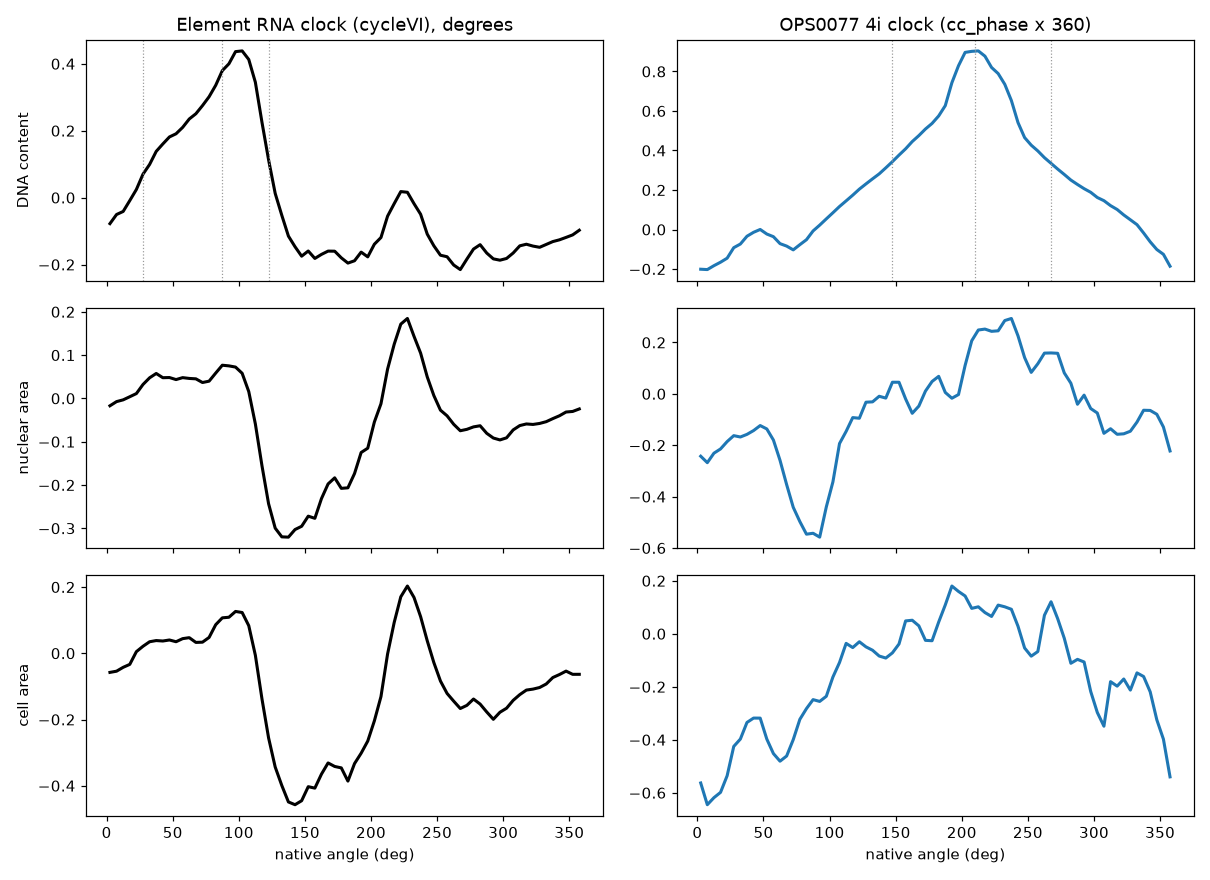

In [4]:
display(Image(filename=find('cc_align_1_native.png')))

In their native conventions the two clocks look different. Element's DNA rises to a peak near 100 degrees and then **collapses
within about 30 degrees** (cell division), and nuclear and cell area collapse with it. The OPS0077 4i clock has a **tent-shaped DNA
profile**: a long rise, then a **slow decline over about 150 degrees** after the peak.

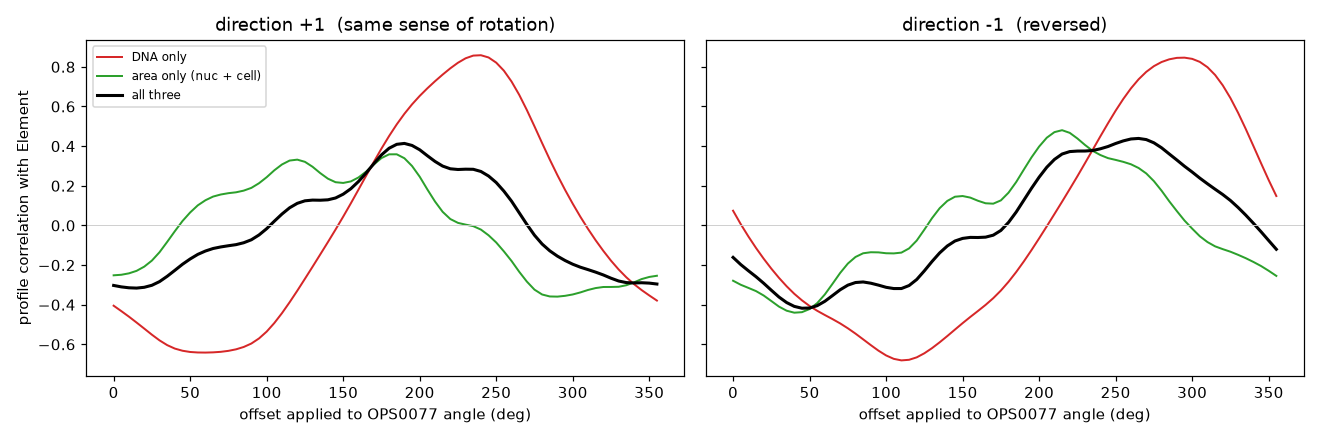

,anchors,best_direction,best_offset_deg,best_profile_corr,bootstrap_direction,bootstrap_pct_same_direction,bootstrap_offset_median_deg,bootstrap_offset_90pct_interval
0,DNA only,1,240.0,0.859,1,100,240,"[235, 240]"
1,area only (nuc + cell),-1,215.0,0.480,-1,100,215,"[210, 215]"
2,all three,-1,265.0,0.439,-1,78,265,"[255, 270]"


In [5]:
display(Image(filename=find('cc_align_2_offset_scan.png')))
pd.read_csv(find('cc_alignment_summary.csv'))

**DNA alone fixes a rotation very precisely.** The table above shows that over 100 bootstrap resamples of the cells the DNA-only fit always has the same direction
(+1, same sense of rotation) and an offset of **240 degrees** (90% interval 235 to 240), profile correlation 0.86. **The anchors do not agree with each other**, though: nuclear and cell area
prefer the reversed direction, and the three together land on yet another solution with a much lower correlation. That disagreement is the main result of this section. The DNA rise and peak
landmarks agree within about 2 degrees under that rotation; the fall landmark is about 24 degrees off, because the OPS0077
decline is much slower than Element's division.

**But the rotation does not carry over to the anchors it never saw.** This table is the profile correlation with Element after each alignment
(DNA is fitted; nuclear and cell area are independent checks):

In [6]:
pd.read_csv(find('cc_alignment_validation.csv')).set_index('alignment').round(3)

,dna r,nuc_area r,cell_area r,"area r (mean of nuc, cell)"
alignment,,,,
unaligned,-0.405,-0.141,-0.362,-0.252
rigid (DNA only),0.859,-0.124,0.082,-0.021
rigid (all three),0.737,0.397,0.186,0.291
landmark warp (DNA only),0.849,0.018,0.056,0.037


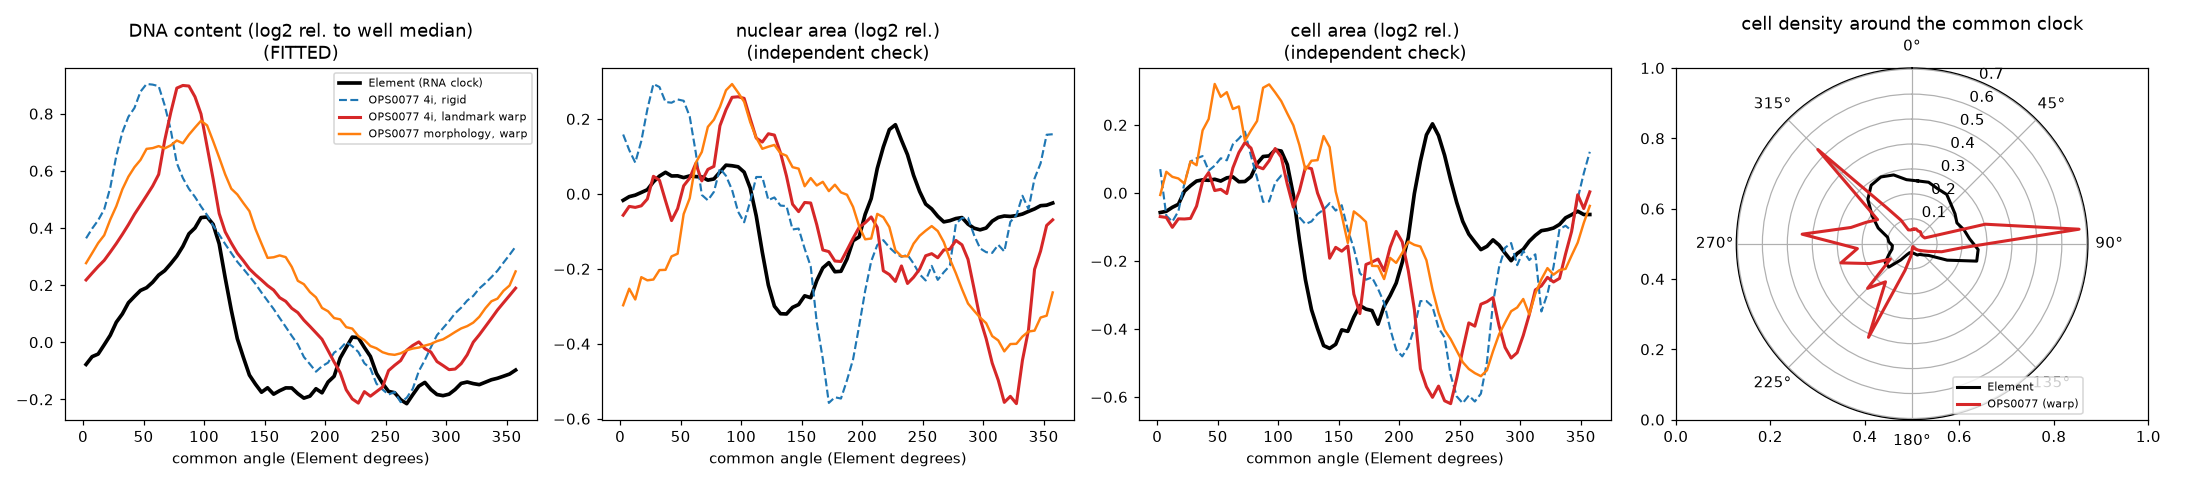

In [7]:
display(Image(filename=find('cc_align_3_aligned.png')))

After the DNA-fitted alignment, nuclear area and cell area are essentially **uncorrelated** with Element's (r about -0.1 and 0.1). A
landmark warp built from the DNA rise, peak and fall does not help, and it piles cells into a few angular ranges
(right panel), which is a sign it is over-fitting DNA.

## 3. Can any re-timing of the clock work? A leave-one-anchor-out test

A rotation may be too rigid, since the two clocks need not move at the same speed through each phase. So we tried **flexible monotone warps**
(4, 6 and 8 knots), always fitting on two anchors and scoring on the third. The honest reference is **a random circular shift of the
held-out Element profile**, which shows how well a map does by chance on smooth curves like these (the curves have only a few independent
features, so apparently good correlations are easy to get).

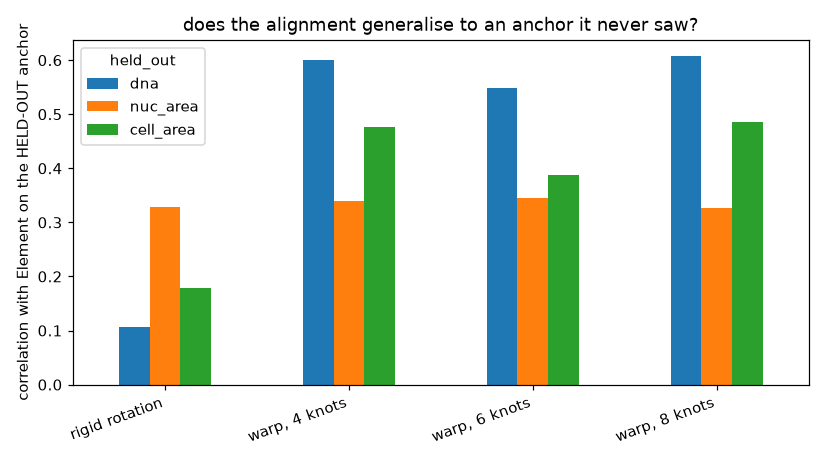

,warp,train_on,held_out,direction,train_corr,HELD_OUT_corr,null_95th,p_vs_random_shift
0,rigid rotation,nuc_area+cell_area,dna,-1,0.481,0.106,0.833,0.403
1,rigid rotation,dna+cell_area,nuc_area,-1,0.474,0.329,0.512,0.194
2,rigid rotation,dna+nuc_area,cell_area,-1,0.568,0.179,0.518,0.361
3,rigid rotation,dna,nuc_area+cell_area,1,0.860,-0.015,0.332,0.556
4,"warp, 4 knots",nuc_area+cell_area,dna,-1,0.727,0.600,0.821,0.194
5,"warp, 4 knots",dna+cell_area,nuc_area,1,0.800,0.339,0.540,0.264
6,"warp, 4 knots",dna+nuc_area,cell_area,-1,0.833,0.477,0.505,0.083
7,"warp, 4 knots",dna,nuc_area+cell_area,-1,0.936,0.416,0.532,0.139
8,"warp, 6 knots",nuc_area+cell_area,dna,-1,0.726,0.548,0.837,0.222
9,"warp, 6 knots",dna+cell_area,nuc_area,1,0.806,0.346,0.531,0.250


In [8]:
display(Image(filename=find('cc_align_5_leave_one_out.png')))
t = pd.read_csv(find('cc_warp_leave_one_anchor_out.csv'))
t[['warp', 'train_on', 'held_out', 'direction', 'train_corr', 'HELD_OUT_corr', 'null_95th', 'p_vs_random_shift']]

**No map generalises.** Held-out correlations (0.1 to 0.6) are never better than a random relative rotation (all p >= 0.07; for
rigid rotations p >= 0.19), and the fitted *direction flips* between folds, which means the anchors do not even agree on which way the
clocks run. Training correlations (0.7 to 0.95) are far above the held-out ones, the signature of over-fitting.

**What we can and cannot say:**
- The **S-phase rise to the G2/M peak** (where DNA is informative) lines up under a rotation of **+240 degrees** (OPS0077 to Element).
- The **G1 and post-division arc is not alignable with these three anchors.** A defensible per-cell mapping between the two datasets is **not** supported yet.
- A plausible reason (not tested here): Element's RNA clock resolves division sharply, while the 4i clock spreads the post-peak decline over about 150 degrees,
  because that arc mixes G2/M and just-divided cells ordered by marker levels.
- To make the alignment identifiable we need **more shared anchors**, for example the many CellProfiler-style cell and nucleus shape
  features that exist in both tables, or Tim's ranking of which features track the RNA clock (`clock_peak_deg` per feature).

## 4. How phase-contrast morphology predicts each regime

Using only label-free phase-contrast morphology (OrganelleProfiler features), we predicted each OPS0077 regime's angle with circular regression
(sin and cosine of the angle), **held-out, with folds grouped by imaging tile**, against a cell-size-only baseline and a shuffled-label null.

In [9]:
a = pd.read_csv(find('phase_predicts_regimes_angles.csv')); a

,target,predictor,circ_r,median_err_deg,balanced_err_deg,within_45deg,n
0,4i DNA,phase-contrast morphology,0.494,29.3,43.8,0.676,35633
1,4i DNA,cell/nuclear size only,-0.009,50.1,89.1,0.469,35633
2,4i markers,phase-contrast morphology,0.650,35.7,48.3,0.588,35633
3,4i markers,cell/nuclear size only,0.172,65.8,87.4,0.363,35633
4,4i DNA+PCs (final),phase-contrast morphology,0.489,29.6,46.8,0.670,35633
5,4i DNA+PCs (final),cell/nuclear size only,0.091,50.4,87.6,0.470,35633
6,4i DNA+PCs (final),shuffled-label null,0.077,53.0,88.6,0.453,35633


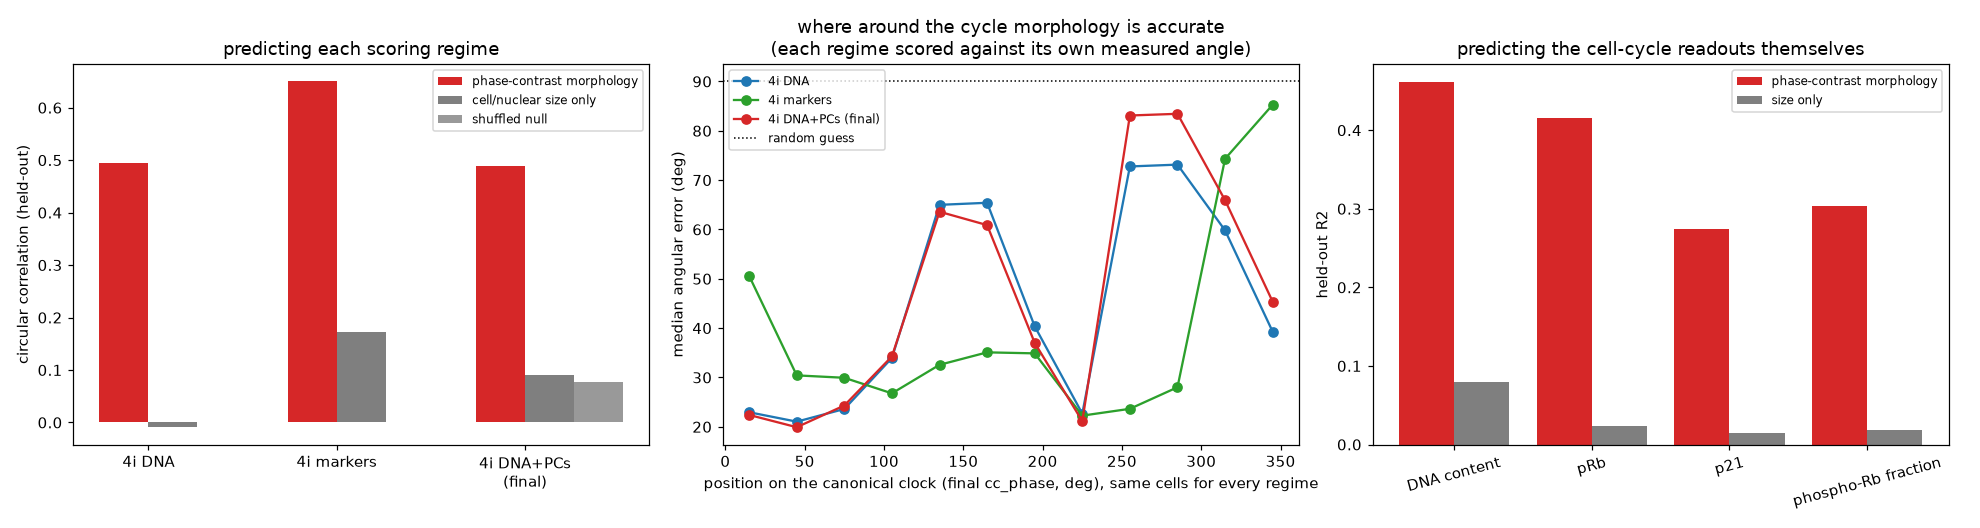

,target,R2 morphology,R2 size only
0,DNA content,0.461,0.079
1,pRb,0.416,0.023
2,p21,0.274,0.015
3,phospho-Rb fraction,0.303,0.019


In [10]:
display(Image(filename=find('cc_align_6_phase_predicts_regimes.png')))
pd.read_csv(find('phase_predicts_regimes_components.csv'))

**Morphology predicts all three regimes, far above cell size.** Circular correlation 0.49 (4i DNA), **0.65 (4i markers)**, 0.49 (final), median
angular error 29 to 36 degrees (random guess: 90), where cell and nuclear size alone give a correlation of about 0 to 0.17.
It predicts the cell-cycle readouts themselves well beyond size too: DNA content R2 0.46, pRb 0.42, p21 0.27, phospho-Rb fraction 0.30
(size alone 0.02 to 0.08). So phase-contrast morphology carries information about the **restriction-point and p21 state, not only DNA content and size**.

**Where around the cycle it is accurate** (middle panel; every regime is plotted against the *same cells'* position on the canonical `cc_phase`, so the regimes are comparable).

In [11]:
arc = pd.read_csv(find('phase_predicts_regimes_by_canonical_arc.csv'))
arc.pivot(index='canonical_arc_deg', columns='regime', values='median_err_deg').reindex(sorted(arc.canonical_arc_deg.unique(), key=lambda s: int(s.split('-')[0])))

regime,4i DNA,4i DNA+PCs (final),4i markers
canonical_arc_deg,,,
0-30,23.0,22.4,50.6
30-60,21.0,19.9,30.4
60-90,23.6,24.3,29.9
90-120,34.0,34.3,26.8
120-150,65.0,63.6,32.6
150-180,65.4,60.9,35.1
180-210,40.4,37.0,34.9
210-240,22.7,21.1,22.3
240-270,72.8,83.1,23.6


**Different regimes are predictable on different arcs.** For cells on the canonical clock at 0 to 90 and 210 to 240 degrees (G1 start and the DNA peak) the DNA-based regimes
are predicted to within about 20 to 25 degrees, and in the arcs at 120 to 180 and 240 to 330 degrees they are poor (60 to 83 degrees). The markers regime is predicted to within
about 22 to 35 degrees across 30 to 300 degrees, including arcs where the DNA-based ones fail, but poorly around the 330 to 30 degree wrap (50 to 85 degrees). The poor arcs are also
the sparsely populated ones for the DNA clock, so some of this is the clock's own resolution (see its clumpy angle in section 1).

In [12]:
print('measured vs predicted-from-morphology angles of the 4i DNA and 4i markers regimes, after the best rotation:')
display(pd.read_csv(find('phase_predicts_regimes_dna_vs_markers.csv')))
print('median angular error after the best rotation; rows = MEASURED regime, columns = regime PREDICTED from morphology:')
pd.read_csv(find('phase_predicts_regimes_cross.csv'), index_col=0)

measured vs predicted-from-morphology angles of the 4i DNA and 4i markers regimes, after the best rotation:


,angles,mean_cos,direction,rotation_deg,median_err_deg
0,measured,0.34,1,142,42
1,predicted from morphology,0.42,-1,56,49


median angular error after the best rotation; rows = MEASURED regime, columns = regime PREDICTED from morphology:


,4i DNA,4i markers,4i DNA+PCs (final)
4i DNA,29.3,66.0,28.8
4i markers,54.9,35.7,54.7
4i DNA+PCs (final),30.8,66.9,29.6


**Each regime is best predicted by a model trained on it.** A morphology model trained on the DNA clock recovers the measured markers angle only to about 55 degrees, and a model trained on the
markers clock recovers the DNA angle only to about 66 degrees (diagonal: 29 to 36 degrees). So morphology carries information about *both* regimes and they are not one shared axis. Between the two
*predicted* angles the best alignment is even a reversal (direction -1, about 49 degrees), so the models do not simply reproduce the measured same-direction relation, and the markers regime is the least
consistent of the three.

## Takeaways and next steps

1. **Within OPS0077**: 4i DNA, DNA+PCs and the final `cc_phase` are one clock (4 to 6 degrees apart). The **markers-only regime is the same cycle in the same direction**, 142 degrees
   rotated (median difference about 40 degrees), but its stored origin is arbitrary (the script's alignment step is rotation-invariant) and over the first part of the DNA clock
   (about 0 to 60 degrees) it runs the other way. The DNA clock angle is also clumpy, which limits angle-based comparisons.
2. **Across datasets**: the S to G2/M arc aligns by a **+240 degree rotation** (OPS0077 to Element RNA clock), tightly identified from DNA (always the same direction, 235 to 240 degrees over 100 bootstraps).
   The G1 and post-division arc **cannot be aligned** with DNA, nuclear area and cell area, and no rigid or flexible map beats chance on held-out anchors (all p >= 0.07). We do not recommend a per-cell cross-dataset angle yet.
3. **Phase-contrast morphology predicts every regime** (circular r 0.49 to 0.65, median error 29 to 36 degrees; size alone is about 0), as well as pRb, p21 and phospho-Rb
   (R2 0.27 to 0.42) beyond DNA content, so it is a sensible common readout across regimes.
4. **Regimes are predictable on different arcs and each is best predicted by its own model**, so a model that predicts the DNA-based and markers angles together may cover more of the cycle.
5. **To align the datasets we need more anchors**: matched CellProfiler-style shape features and the per-feature clock peaks from Tim's ranking.

**For the scoring script (`ops0077_cell_cycle_score.py`)**: in `circ_corr`, use `np.mean(np.cos(2*np.pi*circ_diff(a, b)))` instead of `np.abs(np.mean(np.exp(2j*np.pi*circ_diff(a, b))))`.
The `abs` removes the rotation, so the shift search in the markers alignment cannot choose a shift.